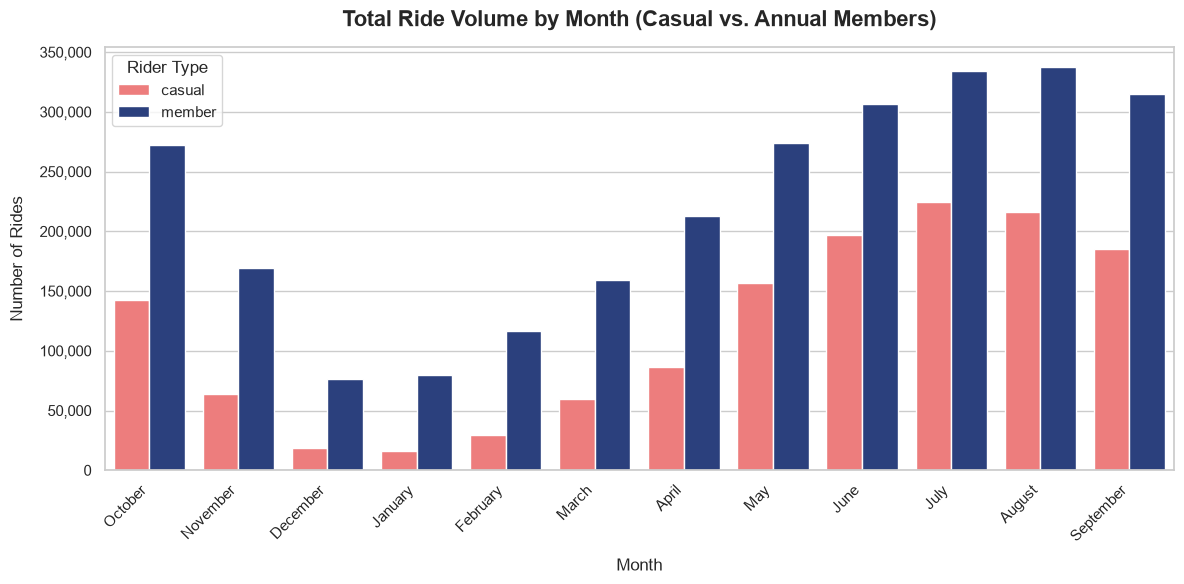

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# 1. Enter the raw data
wide_data = {
    "month": [
        "October", "November", "December", "January",
        "February", "March", "April", "May",
        "June", "July", "August", "September"
    ],
    "casual": [
        142180, 63617, 18640, 16395, 29369, 59799,
        86529, 156703, 196947, 224405, 216458, 185432
    ],
    "member": [
        271971, 169366, 76492, 79736, 116797, 159242,
        212525, 273876, 306437, 334007, 337443, 315079
    ]
}

# 2. Create the DataFrame and reshape for Seaborn
df_wide = pd.DataFrame(wide_data)

monthly_df = df_wide.melt(
    id_vars="month",
    var_name="member_casual",
    value_name="ride_count"
)

# 3. Set the chart style and colors
sns.set_theme(style="whitegrid")

cyclistic_colors = {
    "casual": "#FF6B6B",
    "member": "#1E3A8A"
}

# 4. Create the grouped bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=monthly_df,
    x="month",
    y="ride_count",
    hue="member_casual",
    hue_order=["casual", "member"],
    palette=cyclistic_colors
)

# 5. Format the title and axes
plt.title(
    "Total Ride Volume by Month (Casual vs. Annual Members)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12, labelpad=10)
plt.ylabel("Number of Rides", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}")
)

plt.xticks(rotation=45, ha="right")

plt.legend(
    title="Rider Type",
    fontsize=11,
    title_fontsize=12
)

plt.tight_layout()

# 6. Save and display the chart
plt.savefig("monthly_ride_volume.png", dpi=300, bbox_inches="tight")
plt.show()


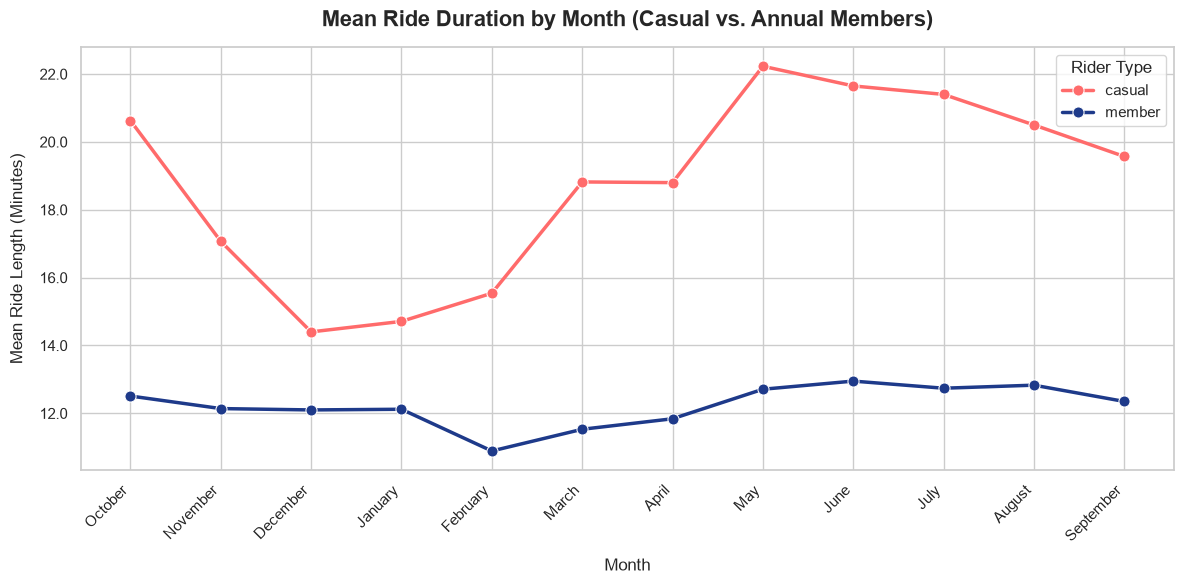

In [8]:

from matplotlib.ticker import FormatStrFormatter

# 1. Enter the raw data
wide_data = {
    "month": [
        "October", "November", "December", "January",
        "February", "March", "April", "May",
        "June", "July", "August", "September"
    ],
    "casual": [
        20.63, 17.07, 14.40, 14.71, 15.54, 18.82,
        18.80, 22.23, 21.65, 21.40, 20.50, 19.57
    ],
    "member": [
        12.51, 12.14, 12.10, 12.12, 10.89, 11.53,
        11.84, 12.71, 12.95, 12.74, 12.83, 12.35
    ]
}

# 2. Create the DataFrame and reshape for Seaborn
df_wide = pd.DataFrame(wide_data)

monthly_df = df_wide.melt(
    id_vars="month",
    var_name="member_casual",
    value_name="mean_ride_length"
)

# 3. Set the chart style and colors
sns.set_theme(style="whitegrid")

cyclistic_colors = {
    "casual": "#FF6B6B",
    "member": "#1E3A8A"
}

# 4. Create the line chart
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=monthly_df,
    x="month",
    y="mean_ride_length",
    hue="member_casual",
    hue_order=["casual", "member"],
    palette=cyclistic_colors,
    marker="o",
    linewidth=2.5,
    markersize=8
)

# 5. Format the title and axes
plt.title(
    "Mean Ride Duration by Month (Casual vs. Annual Members)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12, labelpad=10)
plt.ylabel("Mean Ride Length (Minutes)", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))

plt.xticks(rotation=45, ha="right")

plt.legend(
    title="Rider Type",
    fontsize=11,
    title_fontsize=12
)

plt.tight_layout()

# 6. Save and display the chart
plt.savefig(
    "monthly_mean_ride_length_line.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

findfont: Failed to find font weight medium, now using 400.


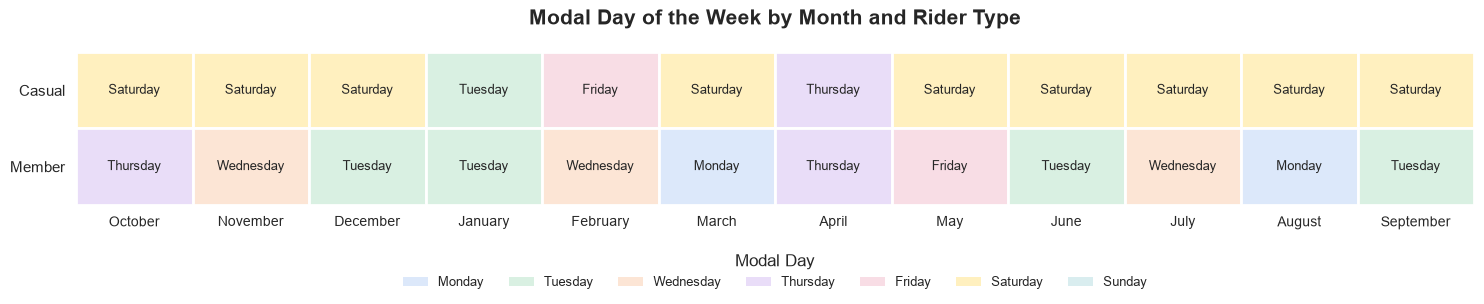

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. Enter your raw data
data = {
    "October":    ["Saturday", "Thursday"],
    "November":   ["Saturday", "Wednesday"],
    "December":   ["Saturday", "Tuesday"],
    "January":    ["Tuesday", "Tuesday"],
    "February":   ["Friday", "Wednesday"],
    "March":      ["Saturday", "Monday"],
    "April":      ["Thursday", "Thursday"],
    "May":        ["Saturday", "Friday"],
    "June":       ["Saturday", "Tuesday"],
    "July":       ["Saturday", "Wednesday"],
    "August":     ["Saturday", "Monday"],
    "September":  ["Saturday", "Tuesday"]
}

# 2. Create a DataFrame
df = pd.DataFrame(
    data,
    index=["Casual", "Member"]
)

# 3. Assign a consistent color to each weekday
day_colors = {
    "Monday": "#DCE8FA",
    "Tuesday": "#D9F0E2",
    "Wednesday": "#FCE5D5",
    "Thursday": "#E9DDF8",
    "Friday": "#F8DDE5",
    "Saturday": "#FFF0BF",
    "Sunday": "#D9EDEF"
}

# 4. Create the figure and axes
fig, ax = plt.subplots(figsize=(15, 3.5))

# Hide the default axes
ax.set_xlim(0, len(df.columns))
ax.set_ylim(0, len(df.index))
ax.invert_yaxis()

ax.set_xticks(
    [i + 0.5 for i in range(len(df.columns))]
)
ax.set_xticklabels(df.columns, fontsize=10)

ax.set_yticks([0.5, 1.5])
ax.set_yticklabels(df.index, fontsize=11)

# 5. Draw colored cells and add weekday labels
for row in range(len(df.index)):
    for col in range(len(df.columns)):
        day = df.iloc[row, col]

        rectangle = plt.Rectangle(
            (col, row),
            1,
            1,
            facecolor=day_colors[day],
            edgecolor="white",
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            col + 0.5,
            row + 0.5,
            day,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="medium"
        )

# 6. Add title and formatting
ax.set_title(
    "Modal Day of the Week by Month and Rider Type",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.tick_params(
    axis="both",
    length=0,
    pad=8
)

for spine in ax.spines.values():
    spine.set_visible(False)

# 7. Add a weekday color legend
legend_items = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=day
    )
    for day, color in day_colors.items()
]

ax.legend(
    handles=legend_items,
    title="Modal Day",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=7,
    frameon=False,
    fontsize=9
)

plt.tight_layout()

# 8. Save and display
plt.savefig(
    "modal_day_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

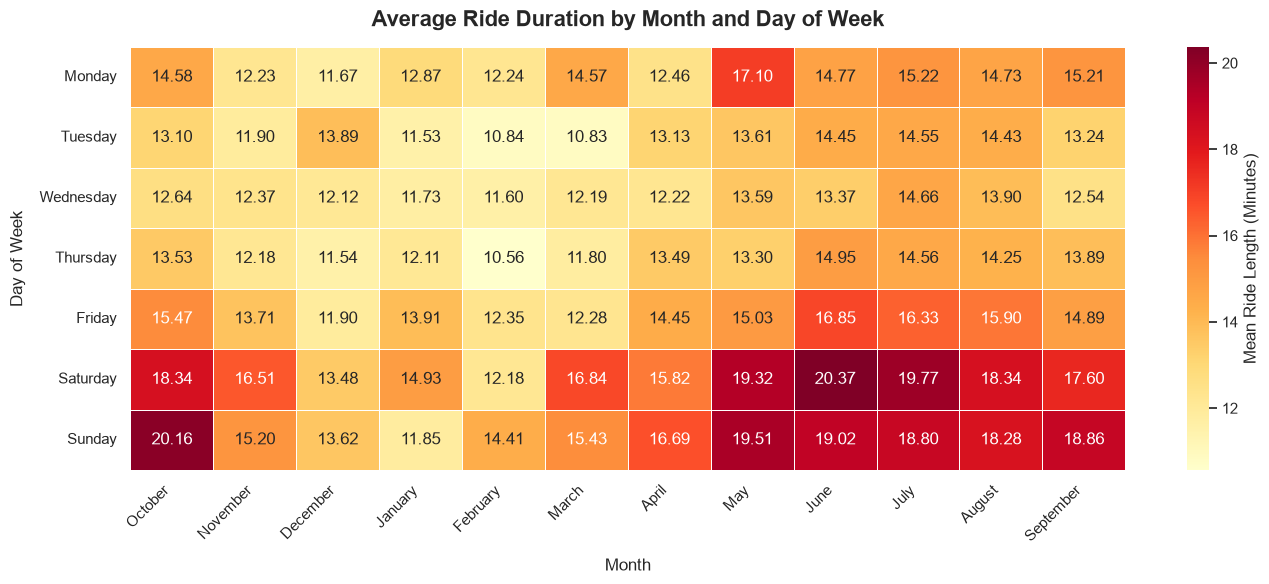

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Enter the raw data
data = {
    "October":    [14.58, 13.10, 12.64, 13.53, 15.47, 18.34, 20.16],
    "November":   [12.23, 11.90, 12.37, 12.18, 13.71, 16.51, 15.20],
    "December":   [11.67, 13.89, 12.12, 11.54, 11.90, 13.48, 13.62],
    "January":    [12.87, 11.53, 11.73, 12.11, 13.91, 14.93, 11.85],
    "February":   [12.24, 10.84, 11.60, 10.56, 12.35, 12.18, 14.41],
    "March":      [14.57, 10.83, 12.19, 11.80, 12.28, 16.84, 15.43],
    "April":      [12.46, 13.13, 12.22, 13.49, 14.45, 15.82, 16.69],
    "May":        [17.10, 13.61, 13.59, 13.30, 15.03, 19.32, 19.51],
    "June":       [14.77, 14.45, 13.37, 14.95, 16.85, 20.37, 19.02],
    "July":       [15.22, 14.55, 14.66, 14.56, 16.33, 19.77, 18.80],
    "August":     [14.73, 14.43, 13.90, 14.25, 15.90, 18.34, 18.28],
    "September":  [15.21, 13.24, 12.54, 13.89, 14.89, 17.60, 18.86]
}

days = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# 2. Create the DataFrame
df = pd.DataFrame(data, index=days)
df.index.name = "Day of Week"

# 3. Set the chart style
sns.set_theme(style="white")

# 4. Create the heatmap
plt.figure(figsize=(14, 6))

ax = sns.heatmap(
    df,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Mean Ride Length (Minutes)"}
)

# 5. Add title and labels
plt.title(
    "Average Ride Duration by Month and Day of Week",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12, labelpad=10)
plt.ylabel("Day of Week", fontsize=12, labelpad=10)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# 6. Save and display
plt.savefig(
    "average_ride_duration_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

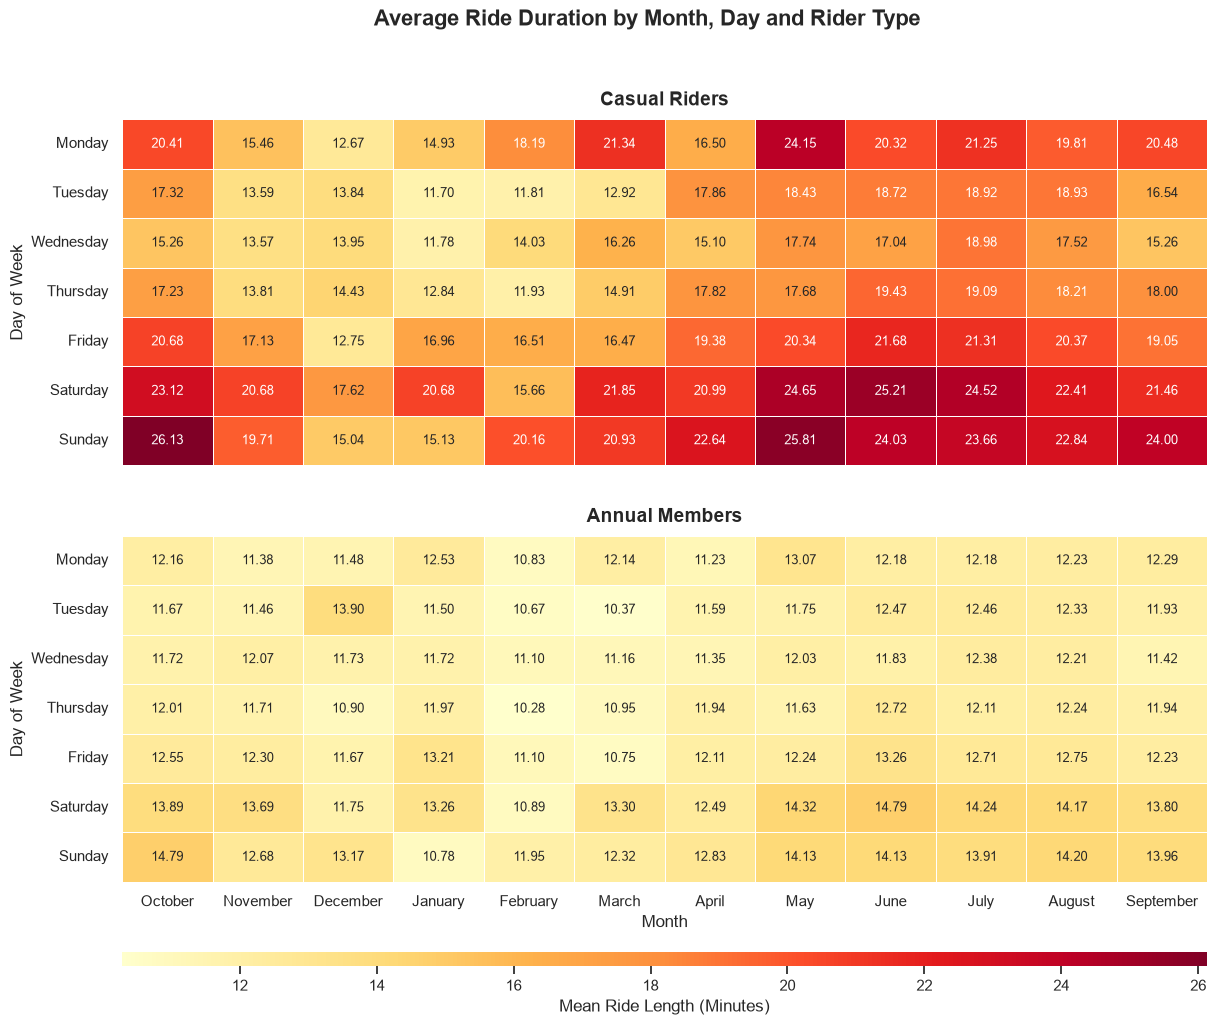

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Define the months and days
months = [
    "October",
    "November",
    "December",
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
]
days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

# 2. Enter the raw data for casual riders
casual_data = [
    [
        20.41,
        15.46,
        12.67,
        14.93,
        18.19,
        21.34,
        16.50,
        24.15,
        20.32,
        21.25,
        19.81,
        20.48,
    ],
    [
        17.32,
        13.59,
        13.84,
        11.70,
        11.81,
        12.92,
        17.86,
        18.43,
        18.72,
        18.92,
        18.93,
        16.54,
    ],
    [
        15.26,
        13.57,
        13.95,
        11.78,
        14.03,
        16.26,
        15.10,
        17.74,
        17.04,
        18.98,
        17.52,
        15.26,
    ],
    [
        17.23,
        13.81,
        14.43,
        12.84,
        11.93,
        14.91,
        17.82,
        17.68,
        19.43,
        19.09,
        18.21,
        18.00,
    ],
    [
        20.68,
        17.13,
        12.75,
        16.96,
        16.51,
        16.47,
        19.38,
        20.34,
        21.68,
        21.31,
        20.37,
        19.05,
    ],
    [
        23.12,
        20.68,
        17.62,
        20.68,
        15.66,
        21.85,
        20.99,
        24.65,
        25.21,
        24.52,
        22.41,
        21.46,
    ],
    [
        26.13,
        19.71,
        15.04,
        15.13,
        20.16,
        20.93,
        22.64,
        25.81,
        24.03,
        23.66,
        22.84,
        24.00,
    ],
]

# 3. Enter the raw data for members
member_data = [
    [
        12.16,
        11.38,
        11.48,
        12.53,
        10.83,
        12.14,
        11.23,
        13.07,
        12.18,
        12.18,
        12.23,
        12.29,
    ],
    [
        11.67,
        11.46,
        13.90,
        11.50,
        10.67,
        10.37,
        11.59,
        11.75,
        12.47,
        12.46,
        12.33,
        11.93,
    ],
    [
        11.72,
        12.07,
        11.73,
        11.72,
        11.10,
        11.16,
        11.35,
        12.03,
        11.83,
        12.38,
        12.21,
        11.42,
    ],
    [
        12.01,
        11.71,
        10.90,
        11.97,
        10.28,
        10.95,
        11.94,
        11.63,
        12.72,
        12.11,
        12.24,
        11.94,
    ],
    [
        12.55,
        12.30,
        11.67,
        13.21,
        11.10,
        10.75,
        12.11,
        12.24,
        13.26,
        12.71,
        12.75,
        12.23,
    ],
    [
        13.89,
        13.69,
        11.75,
        13.26,
        10.89,
        13.30,
        12.49,
        14.32,
        14.79,
        14.24,
        14.17,
        13.80,
    ],
    [
        14.79,
        12.68,
        13.17,
        10.78,
        11.95,
        12.32,
        12.83,
        14.13,
        14.13,
        13.91,
        14.20,
        13.96,
    ],
]

# 4. Convert the data into DataFrames
casual_df = pd.DataFrame(casual_data, index=days, columns=months)
member_df = pd.DataFrame(member_data, index=days, columns=months)

# 5. Set the visual style
sns.set_theme(style="white")

# Use one shared scale for fair comparison
vmin = min(casual_df.min().min(), member_df.min().min())
vmax = max(casual_df.max().max(), member_df.max().max())

# 6. Create 2 rows for heatmaps, plus 1 thin row at the bottom for the horizontal colorbar
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 11),  # Balanced portrait height for Google Docs page scaling
    sharex=False,
    gridspec_kw={"height_ratios": [1, 1, 0.04]},
)

# Plot Casual Riders on Top
sns.heatmap(
    casual_df,
    ax=axes[0],
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    linewidths=0.5,
    linecolor="white",
    cbar=False,
    annot_kws={"size": 9},  # Crisp text rendering inside the report
)

# Plot Annual Members Below
sns.heatmap(
    member_df,
    ax=axes[1],
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    linewidths=0.5,
    linecolor="white",
    cbar_ax=axes[2],
    cbar_kws={"label": "Mean Ride Length (Minutes)", "orientation": "horizontal"},
    annot_kws={"size": 9},
)

# 7. Format the titles and axes
axes[0].set_title("Casual Riders", fontsize=14, fontweight="bold", pad=10)
axes[1].set_title("Annual Members", fontsize=14, fontweight="bold", pad=10)

# Clean up top chart x-axis overlap
axes[0].set_xlabel("")
axes[0].set_xticklabels([])
axes[1].set_xlabel("Month", fontsize=12)

axes[0].set_ylabel("Day of Week", fontsize=12)
axes[1].set_ylabel("Day of Week", fontsize=12)

for ax in [axes[0], axes[1]]:
    ax.tick_params(axis="x", rotation=0)  # Labels sit straight horizontally
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Average Ride Duration by Month, Day and Rider Type",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

# Balanced structural padding
plt.subplots_adjust(hspace=0.3)

# 8. Save and display
plt.savefig(
    "ride_duration_stacked.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

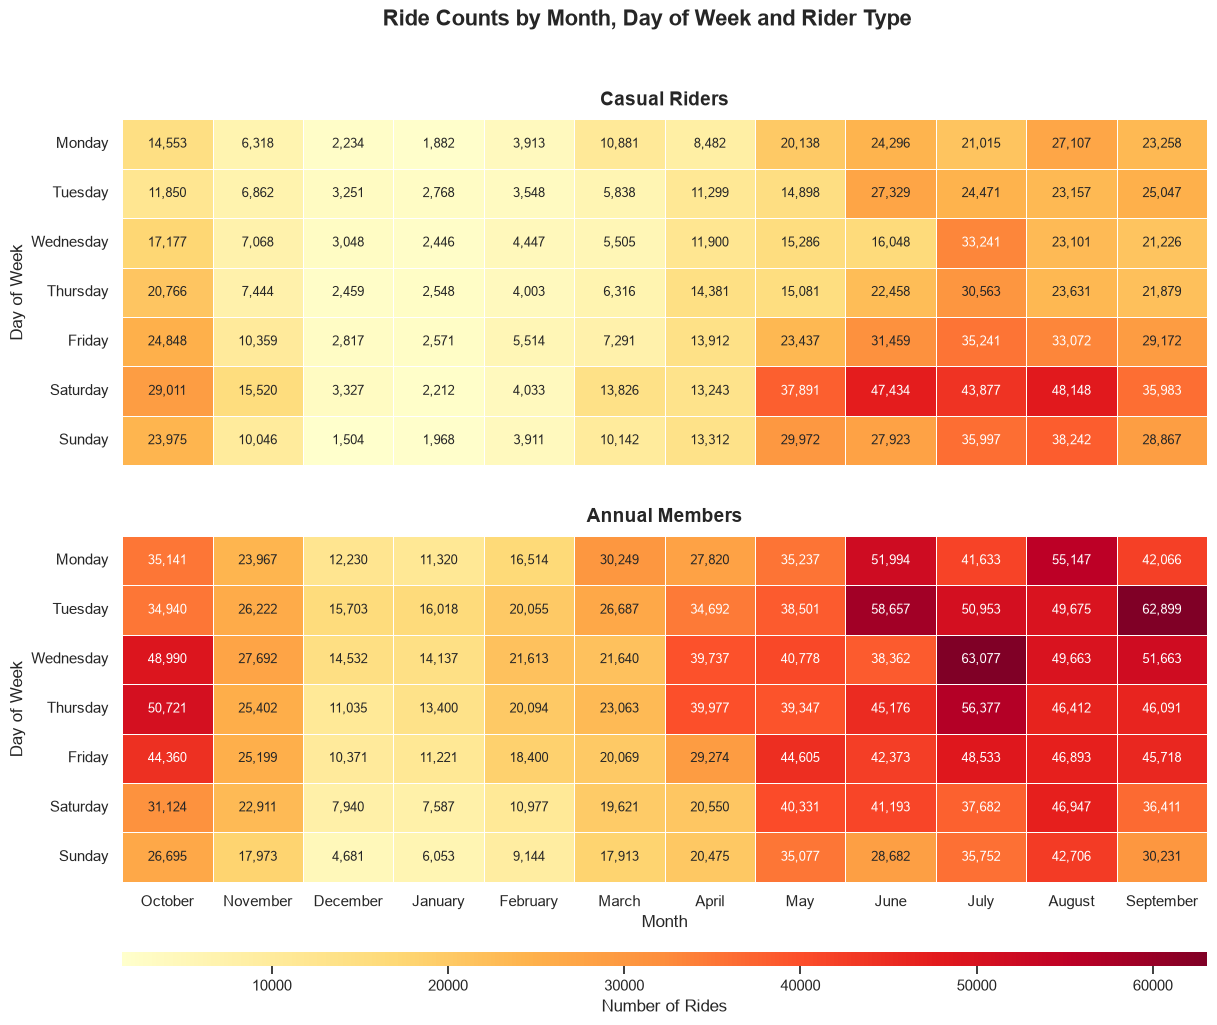

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Define months and days
months = [
    "October",
    "November",
    "December",
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
]

days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

# 2. Ride counts for casual riders
casual_data = [
    [
        14553,
        6318,
        2234,
        1882,
        3913,
        10881,
        8482,
        20138,
        24296,
        21015,
        27107,
        23258,
    ],
    [
        11850,
        6862,
        3251,
        2768,
        3548,
        5838,
        11299,
        14898,
        27329,
        24471,
        23157,
        25047,
    ],
    [
        17177,
        7068,
        3048,
        2446,
        4447,
        5505,
        11900,
        15286,
        16048,
        33241,
        23101,
        21226,
    ],
    [
        20766,
        7444,
        2459,
        2548,
        4003,
        6316,
        14381,
        15081,
        22458,
        30563,
        23631,
        21879,
    ],
    [
        24848,
        10359,
        2817,
        2571,
        5514,
        7291,
        13912,
        23437,
        31459,
        35241,
        33072,
        29172,
    ],
    [
        29011,
        15520,
        3327,
        2212,
        4033,
        13826,
        13243,
        37891,
        47434,
        43877,
        48148,
        35983,
    ],
    [
        23975,
        10046,
        1504,
        1968,
        3911,
        10142,
        13312,
        29972,
        27923,
        35997,
        38242,
        28867,
    ],
]

# 3. Ride counts for annual members
member_data = [
    [
        35141,
        23967,
        12230,
        11320,
        16514,
        30249,
        27820,
        35237,
        51994,
        41633,
        55147,
        42066,
    ],
    [
        34940,
        26222,
        15703,
        16018,
        20055,
        26687,
        34692,
        38501,
        58657,
        50953,
        49675,
        62899,
    ],
    [
        48990,
        27692,
        14532,
        14137,
        21613,
        21640,
        39737,
        40778,
        38362,
        63077,
        49663,
        51663,
    ],
    [
        50721,
        25402,
        11035,
        13400,
        20094,
        23063,
        39977,
        39347,
        45176,
        56377,
        46412,
        46091,
    ],
    [
        44360,
        25199,
        10371,
        11221,
        18400,
        20069,
        29274,
        44605,
        42373,
        48533,
        46893,
        45718,
    ],
    [
        31124,
        22911,
        7940,
        7587,
        10977,
        19621,
        20550,
        40331,
        41193,
        37682,
        46947,
        36411,
    ],
    [
        26695,
        17973,
        4681,
        6053,
        9144,
        17913,
        20475,
        35077,
        28682,
        35752,
        42706,
        30231,
    ],
]

# 4. Create DataFrames
casual_df = pd.DataFrame(casual_data, index=days, columns=months)
member_df = pd.DataFrame(member_data, index=days, columns=months)

# 5. Set visual style
sns.set_theme(style="white")
vmin = min(casual_df.min().min(), member_df.min().min())
vmax = max(casual_df.max().max(), member_df.max().max())

# 6. Create 2 rows for heatmaps, plus 1 thin row at the bottom for the horizontal colorbar
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 11),  # Adjusted aspect ratio for portrait layout documents
    sharex=False,
    gridspec_kw={"height_ratios": [1, 1, 0.04]},
)

# Plot Casual Riders on Top
sns.heatmap(
    casual_df,
    ax=axes[0],
    annot=True,
    fmt=",d",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    linewidths=0.5,
    linecolor="white",
    cbar=False,
    annot_kws={"size": 9},  # Shrink cell font slightly for crisp document rendering
)

# Plot Annual Members Below
sns.heatmap(
    member_df,
    ax=axes[1],
    annot=True,
    fmt=",d",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    linewidths=0.5,
    linecolor="white",
    cbar_ax=axes[2],
    cbar_kws={"label": "Number of Rides", "orientation": "horizontal"},
    annot_kws={"size": 9},
)

# 7. Add titles and labels
axes[0].set_title("Casual Riders", fontsize=14, fontweight="bold", pad=10)
axes[1].set_title("Annual Members", fontsize=14, fontweight="bold", pad=10)

# Hide x-labels on top heatmap so text doesn't overlap the bottom heatmap
axes[0].set_xlabel("")
axes[0].set_xticklabels([])
axes[1].set_xlabel("Month", fontsize=12)

axes[0].set_ylabel("Day of Week", fontsize=12)
axes[1].set_ylabel("Day of Week", fontsize=12)

for ax in [axes[0], axes[1]]:
    ax.tick_params(axis="x", rotation=0)  # Horizontal layout reads easier without 45 deg tilt
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Ride Counts by Month, Day of Week and Rider Type",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

# Control padding explicitly to prevent overlapping
plt.subplots_adjust(hspace=0.3)

# 8. Save and display
plt.savefig(
    "ride_counts_stacked.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

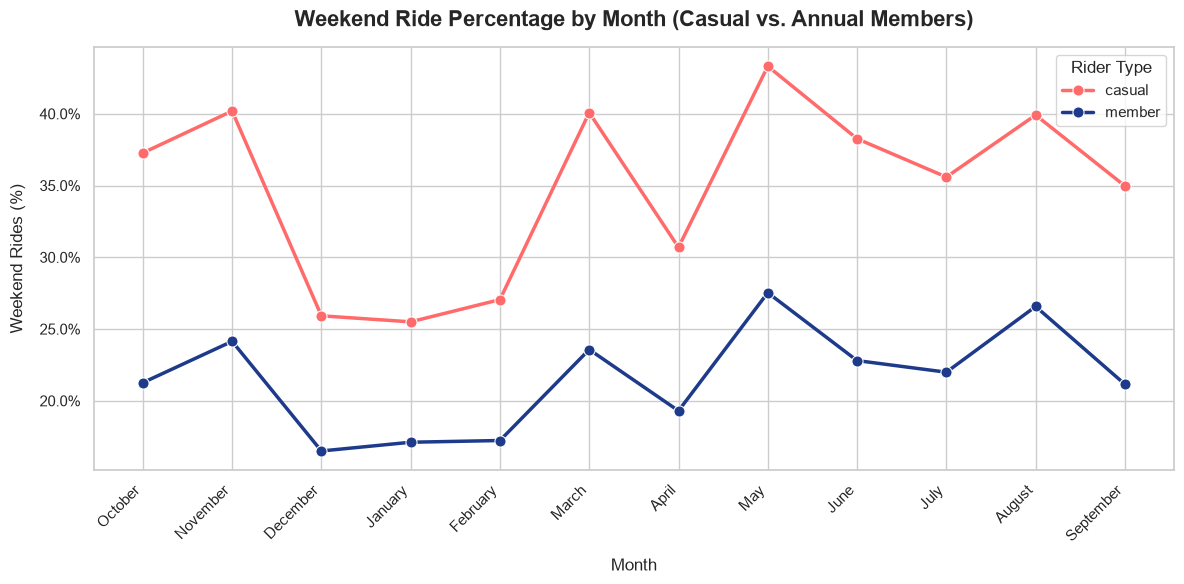

In [9]:

from matplotlib.ticker import FormatStrFormatter

# 1. Enter the raw data
wide_data = {
    "month": [
        "October", "November", "December", "January",
        "February", "March", "April", "May",
        "June", "July", "August", "September"
    ],
    "casual": [
        37.27, 40.19, 25.92, 25.50, 27.05, 40.08,
        30.69, 43.31, 38.26, 35.59, 39.91, 34.97
    ],
    "member": [
        21.26, 24.14, 16.50, 17.11, 17.23, 23.57,
        19.30, 27.53, 22.80, 21.99, 26.57, 21.15
    ]
}

# 2. Create the DataFrame and reshape for Seaborn
df_wide = pd.DataFrame(wide_data)

monthly_df = df_wide.melt(
    id_vars="month",
    var_name="member_casual",
    value_name="weekend_percentage"
)

# 3. Set the chart style and colors
sns.set_theme(style="whitegrid")

cyclistic_colors = {
    "casual": "#FF6B6B",
    "member": "#1E3A8A"
}

# 4. Create the line chart
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=monthly_df,
    x="month",
    y="weekend_percentage",
    hue="member_casual",
    hue_order=["casual", "member"],
    palette=cyclistic_colors,
    marker="o",
    linewidth=2.5,
    markersize=8
)

# 5. Format the title and axes
plt.title(
    "Weekend Ride Percentage by Month (Casual vs. Annual Members)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Month", fontsize=12, labelpad=10)
plt.ylabel("Weekend Rides (%)", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f%%"))

plt.xticks(rotation=45, ha="right")

plt.legend(
    title="Rider Type",
    fontsize=11,
    title_fontsize=12
)

plt.tight_layout()

# 6. Save and display the chart
plt.savefig(
    "monthly_weekend_percentage_line.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

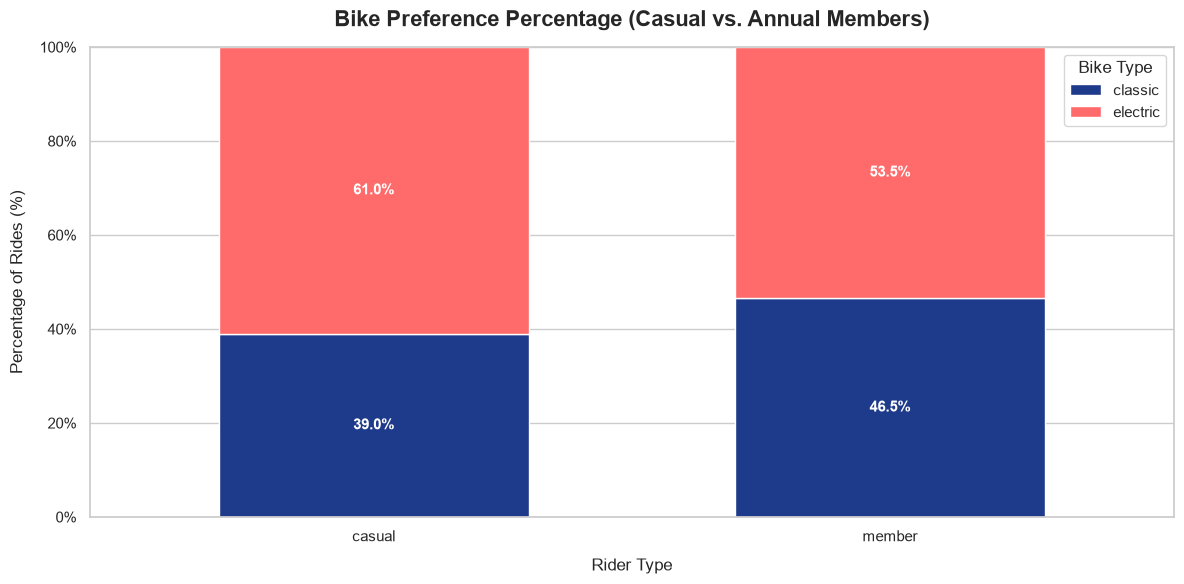

In [6]:

from matplotlib.ticker import FormatStrFormatter

# 1. Enter the raw data
wide_data = {
    "member_casual": ["casual", "member"],
    "classic": [38.973944, 46.533641],
    "electric": [61.026056, 53.466359]
}

# 2. Create the DataFrame and reshape for plotting
df_wide = pd.DataFrame(wide_data)

bike_df = df_wide.melt(
    id_vars="member_casual",
    var_name="rideable_type",
    value_name="percentage"
)

bike_df["rideable_type"] = pd.Categorical(
    bike_df["rideable_type"],
    categories=["classic", "electric"],
    ordered=True
)

bike_df = bike_df.pivot(
    index="member_casual",
    columns="rideable_type",
    values="percentage"
).reindex(["casual", "member"])

# 3. Set the chart style and colors
sns.set_theme(style="whitegrid")

bike_colors = {
    "classic": "#1E3A8A",
    "electric": "#FF6B6B"
}

# 4. Create the 100% stacked bar chart
plt.figure(figsize=(12, 6))

ax = bike_df.plot(
    kind="bar",
    stacked=True,
    color=[bike_colors["classic"], bike_colors["electric"]],
    width=0.6,
    ax=plt.gca()
)

# Add percentage labels inside each bar segment
for container in ax.containers:
    labels = [f"{bar.get_height():.1f}%" for bar in container]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=11,
        fontweight="bold",
        color="white"
    )

# 5. Format the title and axes
plt.title(
    "Bike Preference Percentage (Casual vs. Annual Members)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Rider Type", fontsize=12, labelpad=10)
plt.ylabel("Percentage of Rides (%)", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f%%"))
ax.set_ylim(0, 100)

plt.xticks(rotation=0)

plt.legend(
    title="Bike Type",
    fontsize=11,
    title_fontsize=12
)

plt.tight_layout()

# 6. Save and display the chart
plt.savefig(
    "bike_preference_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

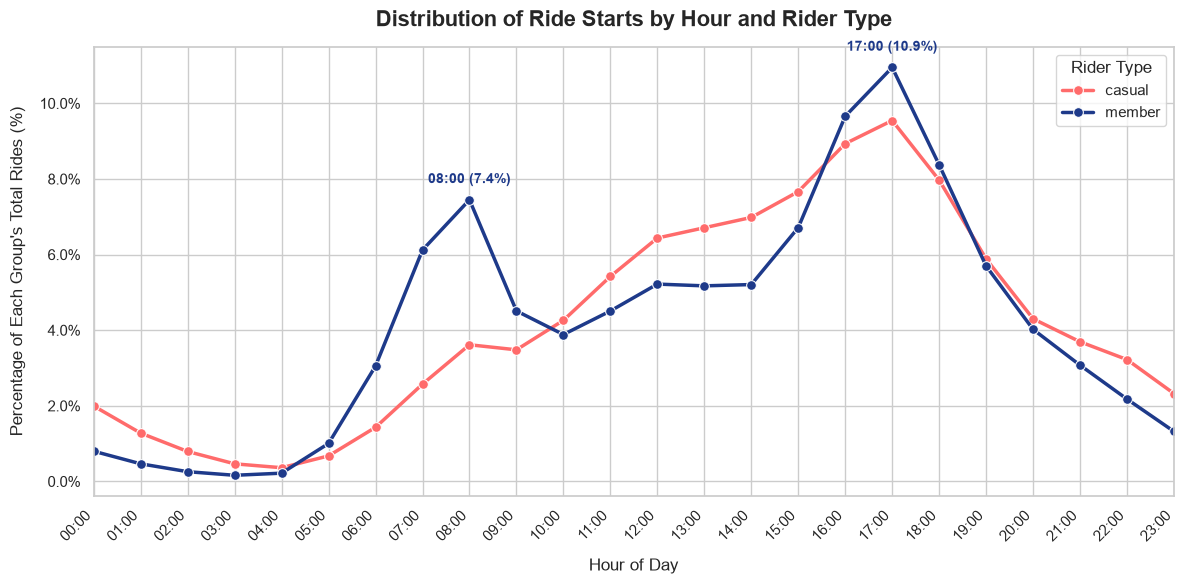

In [7]:

# 1. Enter the raw data
wide_data = {
    "hour": list(range(24)),
    "casual": [
        27833, 17830, 11050, 6491, 5050, 9421,
        19978, 35924, 50469, 48599, 59487, 75711,
        89886, 93686, 97495, 107035, 124749, 133298,
        111272, 82176, 60056, 51562, 44985, 32431
    ],
    "member": [
        21173, 12339, 6813, 4287, 5774, 26614,
        80963, 162353, 197617, 119613, 103059, 119576,
        138447, 137210, 138120, 178072, 256207, 290494,
        222125, 151147, 106659, 81535, 57748, 35026
    ]
}

# 2. Create the DataFrame and reshape for Seaborn
df_wide = pd.DataFrame(wide_data)

hourly_df = df_wide.melt(
    id_vars="hour",
    var_name="member_casual",
    value_name="ride_count"
)

# Calculate each group's hourly percentage of total rides
hourly_df["percentage"] = (
    hourly_df["ride_count"]
    / hourly_df.groupby("member_casual")["ride_count"].transform("sum")
    * 100
)

# 3. Set the chart style and colors
sns.set_theme(style="whitegrid")

cyclistic_colors = {
    "casual": "#FF6B6B",
    "member": "#1E3A8A"
}

# 4. Create the line chart
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=hourly_df,
    x="hour",
    y="percentage",
    hue="member_casual",
    hue_order=["casual", "member"],
    palette=cyclistic_colors,
    marker="o",
    linewidth=2.5,
    markersize=7
)

# 5. Highlight the member morning and evening peaks
member_peaks = hourly_df[
    (hourly_df["member_casual"] == "member")
    & (hourly_df["hour"].isin([8, 17]))
]

for _, row in member_peaks.iterrows():
    ax.annotate(
        f"{row['hour']:02d}:00 ({row['percentage']:.1f}%)",
        xy=(row["hour"], row["percentage"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=cyclistic_colors["member"]
    )

# 6. Format the title and axes
plt.title(
    "Distribution of Ride Starts by Hour and Rider Type",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Hour of Day", fontsize=12, labelpad=10)
plt.ylabel("Percentage of Each Group's Total Rides (%)", fontsize=12, labelpad=10)

ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f%%"))

plt.xticks(
    ticks=range(24),
    labels=[f"{hour:02d}:00" for hour in range(24)],
    rotation=45,
    ha="right"
)

plt.xlim(0, 23)

plt.legend(
    title="Rider Type",
    fontsize=11,
    title_fontsize=12
)

plt.tight_layout()

# 7. Save and display the chart
plt.savefig(
    "hourly_ride_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

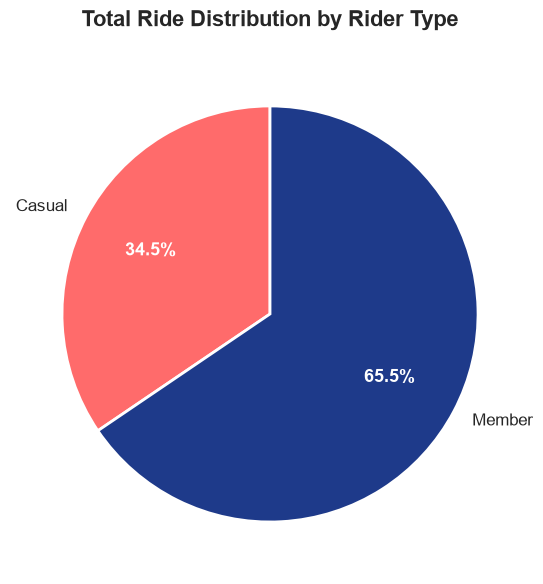

In [12]:

# 1. Enter the raw data
ride_data = {
    "member_casual": ["casual", "member"],
    "ride_count": [1396474, 2652971]
}

# 2. Create the DataFrame
df = pd.DataFrame(ride_data)

# 3. Set the chart style and colors
sns.set_theme(style="whitegrid")

cyclistic_colors = {
    "casual": "#FF6B6B",
    "member": "#1E3A8A"
}

colors = [
    cyclistic_colors[rider]
    for rider in df["member_casual"]
]

# 4. Create the pie chart
plt.figure(figsize=(8, 6))

plt.pie(
    df["ride_count"],
    labels=df["member_casual"].str.capitalize(),
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    textprops={"fontsize": 12},
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    pctdistance=0.65
)

# Format percentage labels separately
for text in plt.gca().texts:
    if "%" in text.get_text():
        text.set_color("white")
        text.set_fontweight("bold")
        text.set_fontsize(13)

# 5. Format the title
plt.title(
    "Total Ride Distribution by Rider Type",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

# 6. Save and display the chart
plt.savefig(
    "total_ride_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()